<a href="https://colab.research.google.com/github/agnal202/ML-visualized/blob/main/Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# @title
# 1. Start with a clean base style
plt.style.use('seaborn-v0_8-whitegrid')

# 2. Define your global styling dictionary
custom_rc = {
    # Figure & Canvas backgrounds
    'figure.facecolor': '#282A2C',    # Dark charcoal outside the plot
    'axes.facecolor': '#2a2a32',      # Slightly lighter charcoal inside the plot

    # Text colors and sizes
    'text.color': 'white',
    'axes.labelcolor': 'white',
    'xtick.color': 'white',
    'ytick.color': 'white',
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.titlepad': 12,
    'axes.labelsize': 10,
    'axes.labelweight': 'bold',

    # Grid lines
    'grid.color': '#444452',
    'grid.linestyle': '--',
    'grid.linewidth': 0.7,

    # Borders (Spines)
    'axes.edgecolor': '#444452',
    'axes.linewidth': 0.8,

    # Legend aesthetics
    'legend.facecolor': '#2a2a32',
    'legend.edgecolor': '#444452',
    'legend.fontsize': 9
}

# 3. Apply the custom settings globally
plt.rcParams.update(custom_rc)

### **Generating a Linear Function with noise**

In [ ]:
W_true = 1.6
B_true = 2.9
spread = 8
N = 200
x_max = 10

X = np.random.rand(N) * x_max

spread_distr = (1 - abs((x_max/2) - X)/(x_max/1.6)) * (np.random.rand(N) * spread - spread/2)

Y = W_true * X + B_true + spread_distr


### **Plotting the Values**

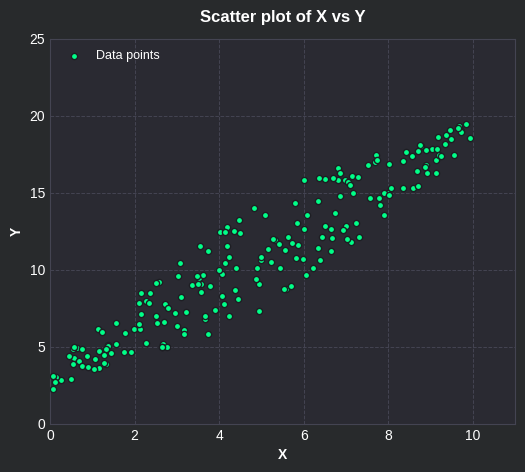

In [ ]:
# @title

fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(X, Y, color='#00ff88', edgecolor='#1e1e24', s=20, label='Data points', zorder=3)

ax.set_xlim(0, 11)
ax.set_ylim(0, 25)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Scatter plot of X vs Y')

ax.grid(True, zorder=1)

legend = ax.legend(labelcolor='white', loc='upper left')

plt.show()

###**Plotting the Mean Squared Error**
<font size="4">
$$\text{MSE} = \frac{1}{N} \sum_{i=1}^{N} (y_i - (w \cdot x_i + b))^2$$
</font>

* **Left Plot :** Change in MSE when the weight ($w$) is varying while the bias ($b$) is kept optimal.
    
* **Right Plot :** Change in MSE when the the bias ($b$) is varying while the weight ($w$) is kept optimal.



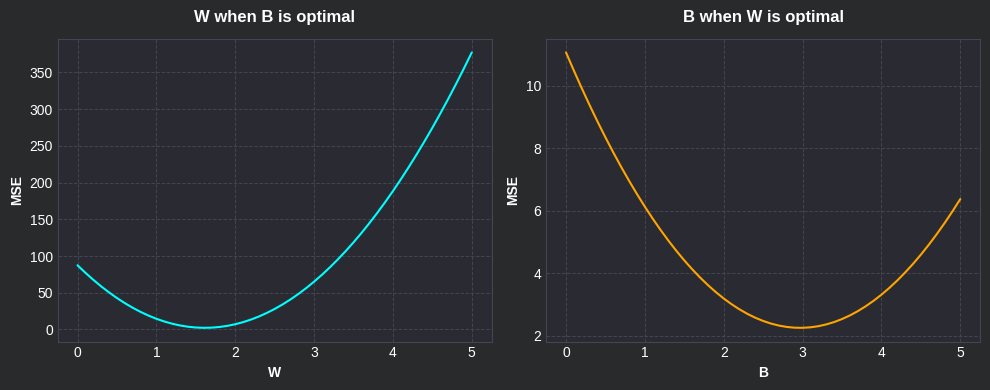

In [ ]:
# @title
w_values = np.arange(0, 5.1, 0.1)
b_values = np.arange(0, 5.1, 0.1)

MSE_w = np.array([])

for w in w_values:
  MSE_w = np.append(MSE_w, ((Y - (w * X + B_true))**2).mean())

MSE_b = np.array([])

for b in b_values:
  MSE_b = np.append(MSE_b, ((Y - (W_true * X + b))**2).mean())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(w_values, MSE_w, color='cyan', label='W')
ax1.set_title('W when B is optimal')
ax1.set_xlabel('W')
ax1.set_ylabel('MSE')
ax1.grid(True)

ax2.plot(b_values, MSE_b, color='orange', label='B')
ax2.set_title('B when W is optimal')
ax2.set_xlabel('B')
ax2.set_ylabel('MSE')
ax2.grid(True)

plt.tight_layout()
plt.show()

### **Gradients with respect to $w$ and $b$**

$$\frac{\partial \text{MSE}}{\partial w} = -\frac{2}{N} \sum_{i=1}^{N} x_i (y_i - (w \cdot x_i + b)) \qquad
\frac{\partial \text{MSE}}{\partial b} = -\frac{2}{N} \sum_{i=1}^{N} (y_i - (w \cdot x_i + b))$$

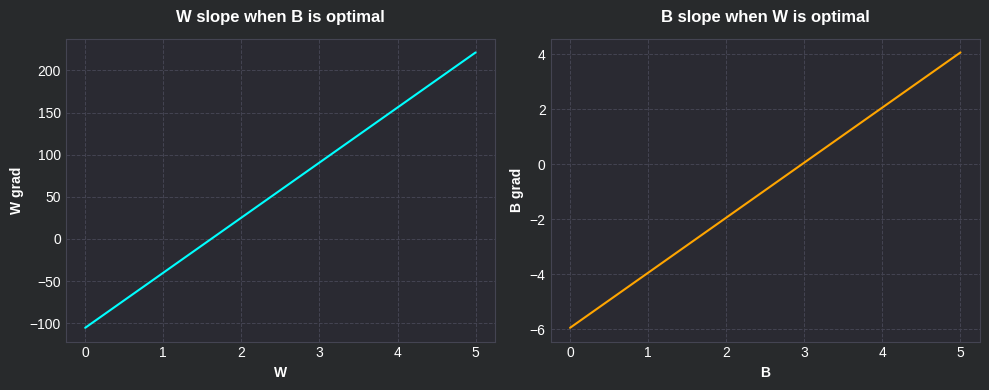

In [ ]:
# @title
w_grad = np.array([])

for w in w_values:
  w_grad = np.append(w_grad, (-2 * (Y - (w * X + B_true)) * X ).mean())

b_grad = np.array([])

for b in b_values:
  b_grad = np.append(b_grad, (-2 *(Y - (W_true * X + b))).mean())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(w_values, w_grad, color='cyan', label='W')
ax1.set_title('W slope when B is optimal')
ax1.set_xlabel('W')
ax1.set_ylabel('W grad')
ax1.grid(True)

ax2.plot(b_values, b_grad, color='orange', label='B')
ax2.set_title('B slope when W is optimal')
ax2.set_xlabel('B')
ax2.set_ylabel('B grad')
ax2.grid(True)

plt.tight_layout()
plt.show()


### **Training Linear Regression Model**

$$\begin{aligned}
w &\leftarrow w - \alpha \cdot \nabla w\\
b &\leftarrow b - \alpha \cdot \nabla b
\end{aligned}$$


In [ ]:
# @title
rnd = lambda x: round(x, 2)

def Loss(X, Y, w, b):
 return ((Y - (w * X + b))**2).mean()

def LinearRegression(X, Y , LearningRate= 0.001, epochs=5000):
  w = b = 0

  for epoch in range(epochs):
    Y_hat = w * X + b

    w_grad = (-2 * (Y - Y_hat) * X).mean()
    b_grad = (-2 * (Y - Y_hat)).mean()


    w = w - LearningRate * w_grad
    b = b - LearningRate * b_grad

    if (epoch %500 == 0):
      print(f"epoch : {rnd(epoch):>5},   w : {rnd(w):>4},   b : {rnd(b):>4},   Loss : {Loss(X, Y, w, b):>8.4f}")

  return w, b

w, b = LinearRegression(X, Y)
print("\nMean Squared Error : ", Loss(X, Y, w, b))


epoch :     0,   w : 0.13,   b : 0.02,   Loss : 124.5373
epoch :   500,   w : 1.93,   b : 0.85,   Loss :   3.2594
epoch :  1000,   w : 1.86,   b : 1.28,   Loss :   2.8807
epoch :  1500,   w : 1.81,   b : 1.62,   Loss :   2.6441
epoch :  2000,   w : 1.77,   b : 1.89,   Loss :   2.4962
epoch :  2500,   w : 1.74,   b :  2.1,   Loss :   2.4038
epoch :  3000,   w : 1.71,   b : 2.27,   Loss :   2.3461
epoch :  3500,   w : 1.69,   b :  2.4,   Loss :   2.3100
epoch :  4000,   w : 1.67,   b : 2.51,   Loss :   2.2874
epoch :  4500,   w : 1.66,   b : 2.59,   Loss :   2.2734

Mean Squared Error :  2.264564939162226


### **Plotting the Predicted Line**

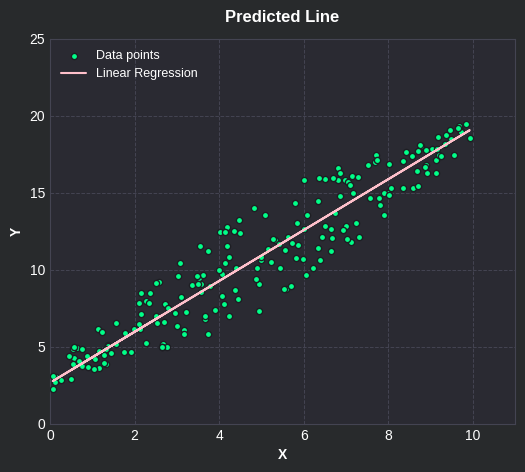

In [ ]:
# @title
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(X, Y, color='#00ff88', edgecolor='#1e1e24', s=20, label='Data points', zorder=3)
ax.plot(X, w * X + b, color='pink', label='Linear Regression', zorder=4)

ax.set_xlim(0, 11)
ax.set_ylim(0, 25)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Predicted Line')

ax.grid(True, zorder=1)

legend = ax.legend(labelcolor='white', loc='upper left')

plt.show()